# 04 | Project Delivery & Process Improvement
Business questions: Which completed projects were late? Which open projects are overdue? Where do milestones tend to slip?


In [ ]:
from pathlib import Path
import os
import sys
import subprocess

# 01 | GitHub repository
REPOSITORY_URL = (
    "https://github.com/MayerAnnamaria/python-business-analytics-project.git"
)

# 02 | Local project directory
PROJECT_DIR = Path("/content/python-business-analytics-project")

# 03 | Clone repository if it does not exist
if not PROJECT_DIR.exists():
    subprocess.run(
        ["git", "clone", REPOSITORY_URL, str(PROJECT_DIR)],
        check=True
    )

# 04 | Install project dependencies
%pip install "pandas>=2.0,<3.0" "numpy>=1.24,<3.0" "matplotlib>=3.7,<4.0" "openpyxl>=3.1,<4.0" "pytest>=7,<10"


# 05 | Set working directory
os.chdir(PROJECT_DIR)

if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

# 06 | Configure input and output folders
INPUT_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "outputs"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 07 | Confirm setup
print("Project:", PROJECT_DIR)
print("Input files:", INPUT_DIR)
print("Output files:", OUTPUT_DIR)
print("Setup completed successfully!")

In [2]:
import matplotlib.pyplot as plt
from src.business_analytics.io import read_sources
from src.business_analytics.cleaning import clean_sources
from src.business_analytics.delivery import project_analysis
tables=clean_sources(read_sources(INPUT_DIR))
projects,milestones,kpis=project_analysis(tables,as_of='2026-01-31')
print(kpis)
display(projects[['project_id','department','status','delay_days','overdue_open','open_days_overdue','late_milestone_pct']].head(12))


{'projects': 24, 'completed_projects': 15, 'on_time_completed_pct': np.float64(46.7), 'open_overdue_projects': 9, 'avg_completed_delay_days': 6.8}


,project_id,department,status,delay_days,overdue_open,open_days_overdue,late_milestone_pct
0,PRJ-001,IT,Completed,-12.0,False,0,75.0
1,PRJ-002,Operations,Completed,0.0,False,0,50.0
2,PRJ-003,Finance,Completed,5.0,False,0,50.0
3,PRJ-004,Customer Service,Completed,18.0,False,0,50.0
4,PRJ-005,Marketing,Completed,26.0,False,0,75.0
5,PRJ-006,HR,Completed,-3.0,False,0,75.0
6,PRJ-007,IT,Completed,9.0,False,0,50.0
7,PRJ-008,Operations,Completed,0.0,False,0,50.0
8,PRJ-009,Finance,Completed,34.0,False,0,50.0
9,PRJ-010,Customer Service,Completed,-8.0,False,0,75.0


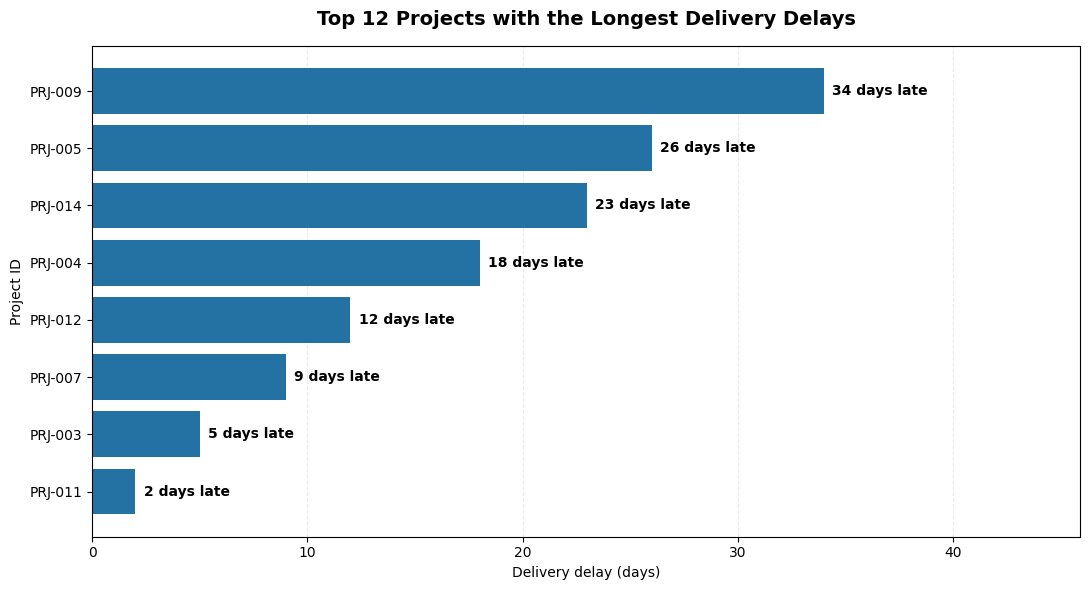

,Rank,Project,Days Late
0,1,PRJ-009,34.0
1,2,PRJ-005,26.0
2,3,PRJ-014,23.0
3,4,PRJ-004,18.0
4,5,PRJ-012,12.0
5,6,PRJ-007,9.0
6,7,PRJ-003,5.0
7,8,PRJ-011,2.0


In [11]:

# =============================================================================
# PROJECT DELIVERY DELAYS | TOP 12 MOST DELAYED PROJECTS
# =============================================================================

import matplotlib.pyplot as plt

# 01 | Identify completed projects with delivery delays
late = projects.loc[
    projects["is_complete"] & (projects["delay_days"] > 0)
].copy()

# 02 | Select the 12 projects with the longest delays
top_delays = late.nlargest(12, "delay_days")

# 03 | Create a horizontal bar chart
fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.barh(
    top_delays["project_id"].astype(str),
    top_delays["delay_days"],
    color="#2471A3"
)

# 04 | Display exact delay duration at the end of each bar
ax.bar_label(
    bars,
    labels=[
        f"{days:.0f} days late"
        for days in top_delays["delay_days"]
    ],
    padding=6,
    fontsize=10,
    fontweight="bold"
)

# 05 | Improve readability
ax.invert_yaxis()
ax.set_xlabel("Delivery delay (days)")
ax.set_ylabel("Project ID")
ax.set_title(
    "Top 12 Projects with the Longest Delivery Delays",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlim(0, top_delays["delay_days"].max() * 1.35)
ax.grid(axis="x", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


# 06 | Display the 12 most delayed projects, ranked by delay duration.

delay_report = (
    top_delays[["project_id", "delay_days"]]
    .sort_values("delay_days", ascending=False)
    .reset_index(drop=True)
    .rename(columns={
        "project_id": "Project",
        "delay_days": "Days Late"
    })
)

# Add sequential ranking, starting with the longest delay.
delay_report.insert(0, "Rank", range(1, len(delay_report) + 1))

display(delay_report)



**Important:** On-time rate denominator includes **completed projects only**. An unfinished overdue project appears in the open-overdue count, not in the completed-project on-time rate. Causes of lateness need investigation.


### Business Findings & Recommendations

**Key Findings**
- **On-time delivery:** Only 46.7% of completed projects were delivered on schedule, highlighting a need for improved delivery performance.
- **Project delays:** The 12 most delayed completed projects were identified and ranked by delay duration.
- **Delivery risks:** Significant delays indicate areas requiring further investigation into project planning, resource allocation, and milestone management.

**Recommended Actions**

1. **Prioritize the most delayed projects:** Review the three projects with the longest delays. Compare planned and actual completion dates, examine milestone histories, and document the reasons for delays with the responsible project managers.

2. **Implement early-warning indicators:** Flag milestones approaching their deadlines that remain incomplete. Establish weekly reviews of upcoming deadlines, overdue milestones, and unresolved dependencies.

3. **Improve schedule estimation:** Compare historical planned versus actual delivery durations. Use the findings to adjust future project schedules, particularly for recurring project types with consistently underestimated timelines.

4. **Strengthen milestone accountability:** Assign a responsible owner and target date to each milestone. Require owners to report blockers and escalate unresolved issues before they affect project deadlines.

5. **Introduce corrective action tracking:** Maintain a centralized action register recording delayed projects, identified causes, responsible owners, corrective actions, and target resolution dates. Review progress weekly.

6. **Monitor improvement:** Track on-time delivery rates, average delay duration, and overdue milestone percentages monthly. Evaluate whether corrective actions reduce delays over subsequent reporting periods.

**Business Objective:** Increase on-time project delivery, reduce avoidable delays, and improve schedule predictability through proactive monitoring and stronger project coordination.

**Success Metrics:** On-time delivery rate (%), average delivery delay (days), overdue milestone rate (%), and corrective action completion rate (%).

**Limitation:** The analysis identifies project delivery delays and quantifies their duration; however, the underlying causes remain undetermined. Further root-cause analysis is recommended to inform targeted corrective actions and improve future delivery performance.